In [1]:
import pandas as pd
import numpy as np


In [2]:
import requests
import pandas as pd

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 50.08,
    "longitude": 7.76,
    "start_date": "2000-01-01",
    "end_date": "2026-09-01",
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "precipitation,"
        "rain,"
        "snowfall,"
        "pressure_msl,"
        "wind_speed_10m,"
        "wind_direction_10m,"
        "et0_fao_evapotranspiration"
    ),
    "timezone": "Europe/Berlin"
}

response = requests.get(url, params=params)

data = response.json()

weather = pd.DataFrame(data["hourly"])

weather["time"] = pd.to_datetime(weather["time"])

print(weather.head())
print(weather.shape)

                 time  temperature_2m  relative_humidity_2m  precipitation  \
0 2000-01-01 00:00:00             1.9                    96            0.0   
1 2000-01-01 01:00:00             1.7                    96            0.0   
2 2000-01-01 02:00:00             1.5                    97            0.0   
3 2000-01-01 03:00:00             1.4                    97            0.0   
4 2000-01-01 04:00:00             1.5                    97            0.0   

   rain  snowfall  pressure_msl  wind_speed_10m  wind_direction_10m  \
0   0.0       0.0        1024.5             5.9                 194   
1   0.0       0.0        1025.0             5.4                 180   
2   0.0       0.0        1024.7             6.9                 189   
3   0.0       0.0        1024.6             6.6                 202   
4   0.0       0.0        1025.0             6.6                 221   

   et0_fao_evapotranspiration  
0                         0.0  
1                         0.0  
2       

In [3]:
weather.head()

,time,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
0,2000-01-01 00:00:00,1.9,96,0.0,0.0,0.0,1024.5,5.9,194,0.0
1,2000-01-01 01:00:00,1.7,96,0.0,0.0,0.0,1025.0,5.4,180,0.0
2,2000-01-01 02:00:00,1.5,97,0.0,0.0,0.0,1024.7,6.9,189,0.0
3,2000-01-01 03:00:00,1.4,97,0.0,0.0,0.0,1024.6,6.6,202,0.0
4,2000-01-01 04:00:00,1.5,97,0.0,0.0,0.0,1025.0,6.6,221,0.0


In [4]:
weather.shape

(233784, 10)

In [5]:
#Checking for the address
import os

print(os.getcwd())

/Users/nabilelfadel/neuefische_course/HydroLoad-AI/notebooks


In [6]:
#checking for the address
import os

print(os.path.exists("data/raw/water_level_15min_kaub.csv"))
print(os.path.exists("../data/raw/water_level_15min_kaub.csv"))

False
True


In [7]:
# Read CSV file for water level for every 15 min
df_water15 = pd.read_csv("../data/raw/water_level_15min_kaub.csv")

df_water15.head()

,timestamp;value
0,2000-01-01 01:00;459
1,2000-01-01 01:15;458
2,2000-01-01 01:30;458
3,2000-01-01 01:45;458
4,2000-01-01 02:00;457


In [8]:
# Read without semicolon
df_water15 = pd.read_csv("../data/raw/water_level_15min_kaub.csv",sep=";")

df_water15.head()

,timestamp,value
0,2000-01-01 01:00,459
1,2000-01-01 01:15,458
2,2000-01-01 01:30,458
3,2000-01-01 01:45,458
4,2000-01-01 02:00,457


In [9]:
# Convert timestamp to datetime
df_water15["timestamp"] = pd.to_datetime(df_water15["timestamp"])

# 15-minute  to hourly mean
df_water_hourly = (
    df_water15
    .set_index("timestamp")
    .resample("1h")["value"]
    .mean()
    .reset_index()
)

df_water_hourly.head()

,timestamp,value
0,2000-01-01 01:00:00,458.25
1,2000-01-01 02:00:00,456.75
2,2000-01-01 03:00:00,455.00
3,2000-01-01 04:00:00,453.00
4,2000-01-01 05:00:00,451.00


In [10]:
# Make sure timestamp is datetime
df_water_hourly["timestamp"] = pd.to_datetime(df_water_hourly["timestamp"])

# Create separate date and time columns
df_water_hourly["date"] = df_water_hourly["timestamp"].dt.date
df_water_hourly["time"] = df_water_hourly["timestamp"].dt.time

# Keep the required columns
df_hourly_water = df_water_hourly[["date", "time", "value"]]

df_hourly_water.head()

,date,time,value
0,2000-01-01,01:00:00,458.25
1,2000-01-01,02:00:00,456.75
2,2000-01-01,03:00:00,455.00
3,2000-01-01,04:00:00,453.00
4,2000-01-01,05:00:00,451.00


In [11]:
# shape of hourly water level data
df_hourly_water.shape

(233783, 3)

In [12]:
weather.head()

,time,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
0,2000-01-01 00:00:00,1.9,96,0.0,0.0,0.0,1024.5,5.9,194,0.0
1,2000-01-01 01:00:00,1.7,96,0.0,0.0,0.0,1025.0,5.4,180,0.0
2,2000-01-01 02:00:00,1.5,97,0.0,0.0,0.0,1024.7,6.9,189,0.0
3,2000-01-01 03:00:00,1.4,97,0.0,0.0,0.0,1024.6,6.6,202,0.0
4,2000-01-01 04:00:00,1.5,97,0.0,0.0,0.0,1025.0,6.6,221,0.0


In [13]:
# Convert to datetime
weather["time"] = pd.to_datetime(weather["time"])

# Create separate date and time columns
weather["date"] = weather["time"].dt.date
weather["time_only"] = weather["time"].dt.time

# Remove original datetime column
weather = weather.drop(columns=["time"])

# Rename time_only to time
weather = weather.rename(columns={"time_only": "time"})

In [14]:
weather = weather[
    ["date", "time"] +
    [col for col in weather.columns if col not in ["date", "time"]]
]

weather.head()

,date,time,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
0,2000-01-01,00:00:00,1.9,96,0.0,0.0,0.0,1024.5,5.9,194,0.0
1,2000-01-01,01:00:00,1.7,96,0.0,0.0,0.0,1025.0,5.4,180,0.0
2,2000-01-01,02:00:00,1.5,97,0.0,0.0,0.0,1024.7,6.9,189,0.0
3,2000-01-01,03:00:00,1.4,97,0.0,0.0,0.0,1024.6,6.6,202,0.0
4,2000-01-01,04:00:00,1.5,97,0.0,0.0,0.0,1025.0,6.6,221,0.0


In [15]:
#drop first row due to time mismatch with water level data
weather = weather.iloc[1:].reset_index(drop=True)

weather.head()

,date,time,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
0,2000-01-01,01:00:00,1.7,96,0.0,0.0,0.0,1025.0,5.4,180,0.0
1,2000-01-01,02:00:00,1.5,97,0.0,0.0,0.0,1024.7,6.9,189,0.0
2,2000-01-01,03:00:00,1.4,97,0.0,0.0,0.0,1024.6,6.6,202,0.0
3,2000-01-01,04:00:00,1.5,97,0.0,0.0,0.0,1025.0,6.6,221,0.0
4,2000-01-01,05:00:00,1.4,97,0.0,0.0,0.0,1025.0,5.9,218,0.0


In [16]:
# Save processed weather data
weather.to_csv("../data/processed/kaub_weather_hourly.csv",index=False)

In [17]:
#water level hourly data
df_hourly_water.head(20)

,date,time,value
0,2000-01-01,01:00:00,458.25
1,2000-01-01,02:00:00,456.75
2,2000-01-01,03:00:00,455.00
3,2000-01-01,04:00:00,453.00
4,2000-01-01,05:00:00,451.00
5,2000-01-01,06:00:00,449.50
6,2000-01-01,07:00:00,447.50
7,2000-01-01,08:00:00,445.00
8,2000-01-01,09:00:00,443.00
9,2000-01-01,10:00:00,441.75


In [18]:
# Save hourly water level data to processed folder
df_hourly_water.to_csv("../data/processed/kaub_water_level_hourly.csv",index=False)

In [19]:
#Checking for the NA's and duplicates
print(df_hourly_water.shape)
print(weather.shape)

print(df_hourly_water.isna().sum())
print(weather.isna().sum())

print(df_hourly_water.duplicated().sum())
print(weather.duplicated().sum())

(233783, 3)
(233783, 11)
date      0
time      0
value    27
dtype: int64
date                          0
time                          0
temperature_2m                0
relative_humidity_2m          0
precipitation                 0
rain                          0
snowfall                      0
pressure_msl                  0
wind_speed_10m                0
wind_direction_10m            0
et0_fao_evapotranspiration    0
dtype: int64
0
0


In [20]:
# Checking for the date and time of both the dataset
print(df_hourly_water[["date", "time"]].head(10))
print(weather[["date", "time"]].head(10))

         date      time
0  2000-01-01  01:00:00
1  2000-01-01  02:00:00
2  2000-01-01  03:00:00
3  2000-01-01  04:00:00
4  2000-01-01  05:00:00
5  2000-01-01  06:00:00
6  2000-01-01  07:00:00
7  2000-01-01  08:00:00
8  2000-01-01  09:00:00
9  2000-01-01  10:00:00
         date      time
0  2000-01-01  01:00:00
1  2000-01-01  02:00:00
2  2000-01-01  03:00:00
3  2000-01-01  04:00:00
4  2000-01-01  05:00:00
5  2000-01-01  06:00:00
6  2000-01-01  07:00:00
7  2000-01-01  08:00:00
8  2000-01-01  09:00:00
9  2000-01-01  10:00:00


In [21]:
#checking for the date and time of the whole dataset
same_date = df_hourly_water["date"].reset_index(drop=True).equals(
    weather["date"].reset_index(drop=True)
)

same_time = df_hourly_water["time"].reset_index(drop=True).equals(
    weather["time"].reset_index(drop=True)
)

print("Dates are same:", same_date)
print("Times are same:", same_time)

Dates are same: True
Times are same: True


In [22]:
# One Final check for the missing data
water_times = set(zip(df_hourly_water["date"], df_hourly_water["time"]))
weather_times = set(zip(weather["date"], weather["time"]))

print("Missing in weather:", len(water_times - weather_times))
print("Missing in water:", len(weather_times - water_times))

Missing in weather: 0
Missing in water: 0


In [23]:
#Merge both data set
merged_df = pd.merge(
   df_hourly_water,
    weather,
    on=["date", "time"],
    how="inner"
)

merged_df.head()

,date,time,value,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
0,2000-01-01,01:00:00,458.25,1.7,96,0.0,0.0,0.0,1025.0,5.4,180,0.0
1,2000-01-01,02:00:00,456.75,1.5,97,0.0,0.0,0.0,1024.7,6.9,189,0.0
2,2000-01-01,03:00:00,455.00,1.4,97,0.0,0.0,0.0,1024.6,6.6,202,0.0
3,2000-01-01,04:00:00,453.00,1.5,97,0.0,0.0,0.0,1025.0,6.6,221,0.0
4,2000-01-01,05:00:00,451.00,1.4,97,0.0,0.0,0.0,1025.0,5.9,218,0.0


In [24]:
print("water level:", df_hourly_water.shape)
print("Weather:", weather.shape)
print("Merged:", merged_df.shape)

water level: (233783, 3)
Weather: (233783, 11)
Merged: (233783, 12)


In [25]:
merged_df.to_csv("../data/processed/kaub_water_weather_hourly.csv",index=False)

In [26]:
import pandas as pd
df = pd.read_csv(
    "../data/processed/kaub_water_weather_hourly.csv"
)

In [27]:
df.head()

,date,time,value,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
0,2000-01-01,01:00:00,458.25,1.7,96,0.0,0.0,0.0,1025.0,5.4,180,0.0
1,2000-01-01,02:00:00,456.75,1.5,97,0.0,0.0,0.0,1024.7,6.9,189,0.0
2,2000-01-01,03:00:00,455.00,1.4,97,0.0,0.0,0.0,1024.6,6.6,202,0.0
3,2000-01-01,04:00:00,453.00,1.5,97,0.0,0.0,0.0,1025.0,6.6,221,0.0
4,2000-01-01,05:00:00,451.00,1.4,97,0.0,0.0,0.0,1025.0,5.9,218,0.0


In [28]:
df.describe()

,value,temperature_2m,relative_humidity_2m,precipitation,rain,snowfall,pressure_msl,wind_speed_10m,wind_direction_10m,et0_fao_evapotranspiration
count,233756.000000,233783.000000,233783.000000,233783.000000,233783.000000,233783.000000,233783.000000,233783.000000,233783.000000,233783.000000
mean,214.470472,10.953399,78.092505,0.077098,0.071668,0.004024,1016.768822,11.136636,203.507163,0.087012
std,100.964117,7.622379,15.986525,0.293270,0.286044,0.042274,8.944724,5.879091,95.013296,0.127278
min,5.000000,-17.700000,15.000000,0.000000,0.000000,0.000000,968.000000,0.000000,1.000000,0.000000
25%,145.000000,5.200000,68.000000,0.000000,0.000000,0.000000,1011.600000,6.800000,130.000000,0.010000
50%,197.000000,10.700000,82.000000,0.000000,0.000000,0.000000,1017.000000,10.000000,224.000000,0.030000
75%,265.000000,16.500000,91.000000,0.000000,0.000000,0.000000,1022.500000,14.600000,272.000000,0.110000
max,719.000000,38.600000,100.000000,14.000000,14.000000,2.520000,1048.200000,48.500000,360.000000,0.860000


In [29]:
df.columns

Index(['date', 'time', 'value', 'temperature_2m', 'relative_humidity_2m',
       'precipitation', 'rain', 'snowfall', 'pressure_msl', 'wind_speed_10m',
       'wind_direction_10m', 'et0_fao_evapotranspiration'],
      dtype='str')

In [30]:
df["value"].describe()

count    233756.000000
mean        214.470472
std         100.964117
min           5.000000
25%         145.000000
50%         197.000000
75%         265.000000
max         719.000000
Name: value, dtype: float64

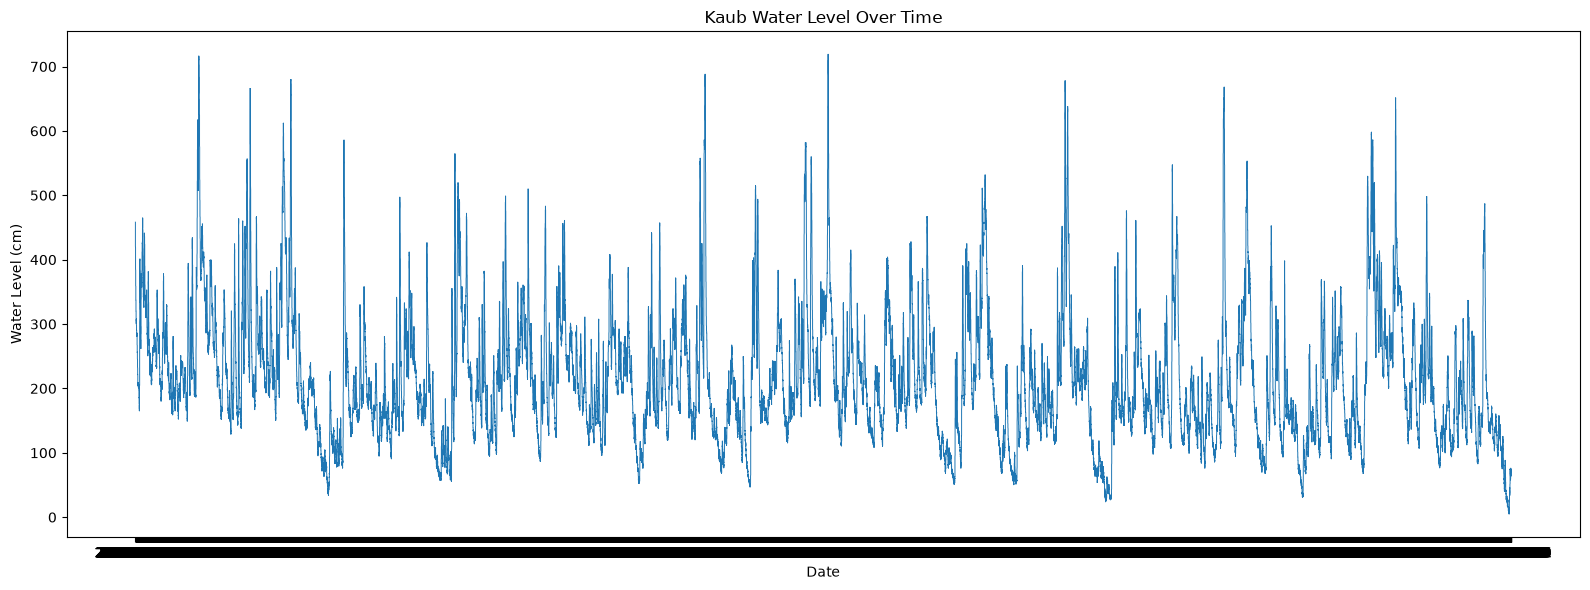

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    df["date"],
    df["value"],
    linewidth=0.7
)

plt.title("Kaub Water Level Over Time")
plt.xlabel("Date")
plt.ylabel("Water Level (cm)")

plt.tight_layout()
plt.show()

In [32]:
df["datetime"] = pd.to_datetime(
    df["date"].astype(str) + " " + df["time"].astype(str)
)

In [33]:
print("Start:", df["datetime"].min())
print("End:", df["datetime"].max())

Start: 2000-01-01 01:00:00
End: 2026-09-01 23:00:00


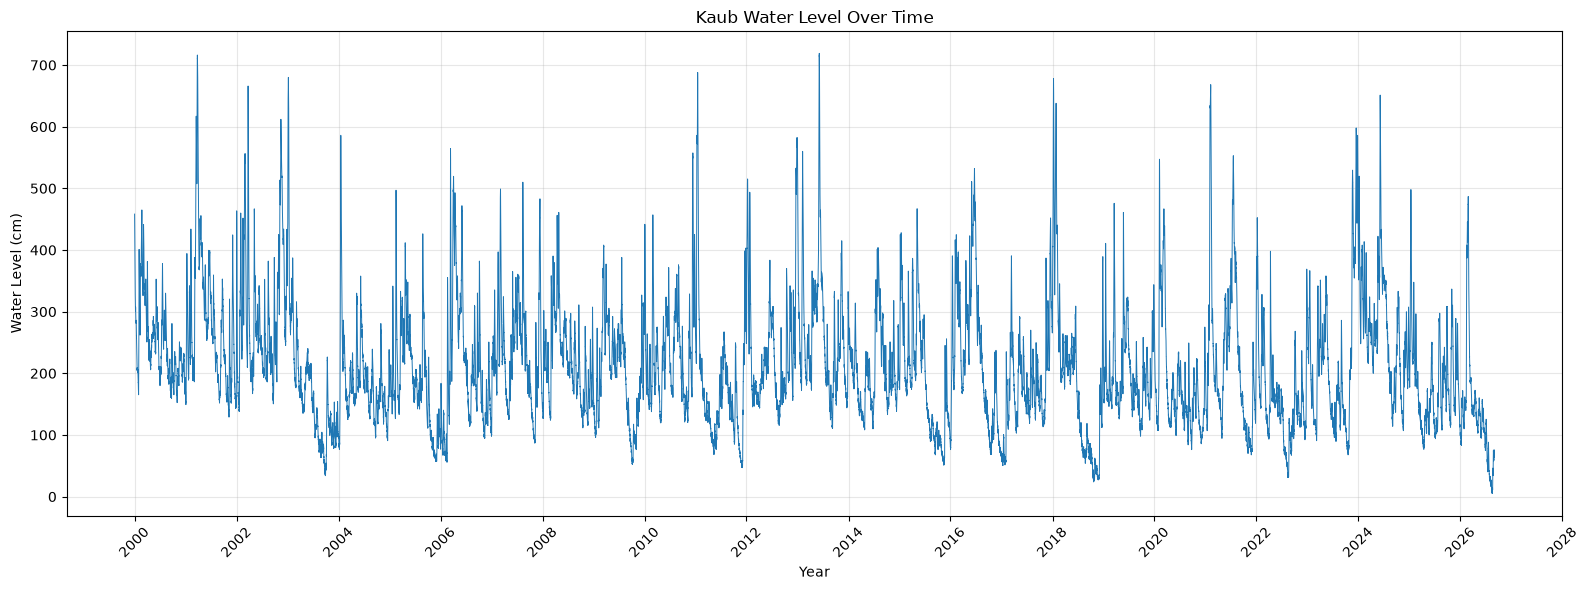

In [34]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

plt.plot(
    df["datetime"],
    df["value"],   # use your actual water-level column
    linewidth=0.7
)

plt.title("Kaub Water Level Over Time")
plt.xlabel("Year")
plt.ylabel("Water Level (cm)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [35]:
df["month"] = df["datetime"].dt.month

In [36]:
monthly_avg = (
    df.groupby("month")["value"]
      .mean()
)

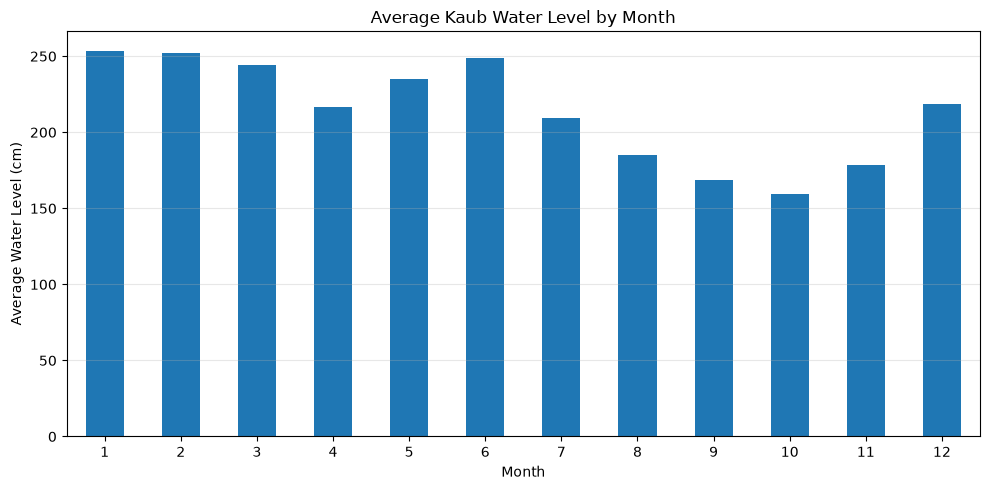

In [37]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

monthly_avg.plot(kind="bar")

plt.title("Average Kaub Water Level by Month")
plt.xlabel("Month")
plt.ylabel("Average Water Level (cm)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.show()

In [38]:
# Make sure datetime exists
df["datetime"] = pd.to_datetime(
    df["date"].astype(str) + " " + df["time"].astype(str)
)

# Daily average from hourly water-level data
daily_water = (
    df.set_index("datetime")["value"]
      .resample("D")
      .mean()
)

# 365-day rolling mean to visualize long-term trend
trend = daily_water.rolling(
    window=365,
    center=True
).mean()

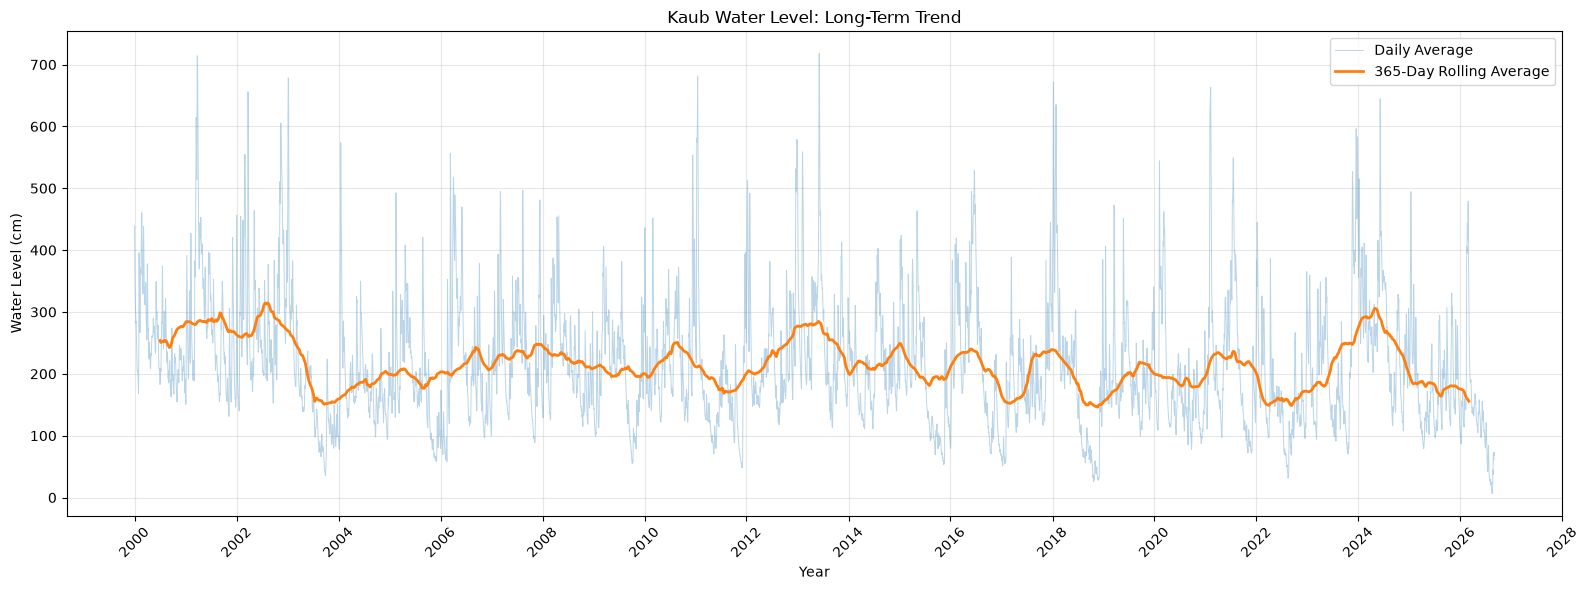

In [39]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.figure(figsize=(16, 6))

# Daily fluctuations
plt.plot(
    daily_water.index,
    daily_water,
    alpha=0.3,
    linewidth=0.7,
    label="Daily Average"
)

# Long-term trend
plt.plot(
    trend.index,
    trend,
    linewidth=2,
    label="365-Day Rolling Average"
)

plt.title("Kaub Water Level: Long-Term Trend")
plt.xlabel("Year")
plt.ylabel("Water Level (cm)")

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.xticks(rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

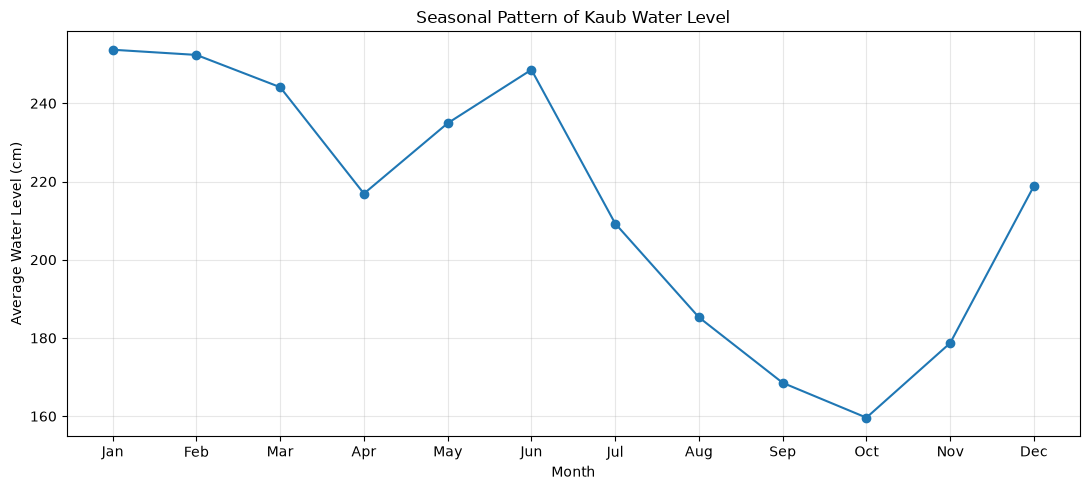

In [40]:
df["month"] = df["datetime"].dt.month
df["year"] = df["datetime"].dt.year

monthly_avg = (
    df.groupby("month")["value"]
      .mean()
)

monthly_avg

import matplotlib.pyplot as plt

month_names = [
    "Jan", "Feb", "Mar", "Apr",
    "May", "Jun", "Jul", "Aug",
    "Sep", "Oct", "Nov", "Dec"
]

plt.figure(figsize=(11, 5))

plt.plot(
    monthly_avg.index,
    monthly_avg.values,
    marker="o"
)

plt.xticks(range(1, 13), month_names)

plt.title("Seasonal Pattern of Kaub Water Level")
plt.xlabel("Month")
plt.ylabel("Average Water Level (cm)")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [41]:
# Make sure date is datetime
merged_df["date"] = pd.to_datetime(merged_df["date"])

# Convert hourly data to daily data
daily_df = merged_df.groupby("date").agg({
    "value": ["mean", "min", "max"],
    "temperature_2m": "mean",
    "relative_humidity_2m": "mean",
    "precipitation": "sum",
    "rain": "sum",
    "snowfall": "sum",
    "pressure_msl": "mean",
    "wind_speed_10m": "mean"
}).reset_index()

In [42]:
daily_df.columns = [
    "date",
    "water_level_mean",
    "water_level_min",
    "water_level_max",
    "temperature_mean",
    "humidity_mean",
    "precipitation_sum",
    "rain_sum",
    "snowfall_sum",
    "pressure_mean",
    "wind_speed_mean"
]

In [43]:
daily_df.head()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean
0,2000-01-01,438.989130,420.75,458.25,3.286957,97.434783,1.7,1.7,0.0,1025.256522,7.773913
1,2000-01-02,401.260417,385.25,419.00,3.979167,96.291667,0.0,0.0,0.0,1030.475000,6.095833
2,2000-01-03,367.989583,359.25,383.50,2.350000,94.458333,0.0,0.0,0.0,1028.470833,11.875000
3,2000-01-04,346.093750,337.00,358.75,5.470833,91.791667,0.8,0.8,0.0,1020.412500,18.445833
4,2000-01-05,327.968750,320.00,337.00,5.495833,89.708333,0.2,0.2,0.0,1021.983333,10.237500


In [44]:
daily_df.shape

(9741, 11)

In [45]:
# Check date range
print("Start:", daily_df["date"].min())
print("End:", daily_df["date"].max())

# Missing values
print(daily_df.isnull().sum())

# Duplicated dates
print("Duplicates:", daily_df["date"].duplicated().sum())

# Basic statistics
daily_df.describe()

Start: 2000-01-01 00:00:00
End: 2026-09-01 00:00:00
date                 0
water_level_mean     0
water_level_min      0
water_level_max      0
temperature_mean     0
humidity_mean        0
precipitation_sum    0
rain_sum             0
snowfall_sum         0
pressure_mean        0
wind_speed_mean      0
dtype: int64
Duplicates: 0


,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean
count,9741,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000
mean,2013-05-02 00:00:00,214.472941,207.926727,221.057309,10.953366,78.092587,1.850334,1.720029,0.096581,1016.768858,11.136621
min,2000-01-01 00:00:00,6.416667,5.000000,8.000000,-10.433333,25.333333,0.000000,0.000000,0.000000,977.212500,1.712500
25%,2006-09-01 00:00:00,145.229167,141.000000,149.250000,5.350000,70.375000,0.000000,0.000000,0.000000,1011.700000,7.450000
50%,2013-05-02 00:00:00,197.020833,191.500000,202.500000,10.920833,79.500000,0.200000,0.200000,0.000000,1016.979167,10.275000
75%,2020-01-01 00:00:00,264.906250,256.500000,273.750000,16.583333,87.250000,2.300000,2.000000,0.000000,1022.279167,13.916667
max,2026-09-01 00:00:00,718.145833,716.500000,719.000000,31.633333,99.708333,38.400000,38.400000,12.810000,1046.666667,37.708333
std,NaN,100.796160,97.779122,103.877220,7.142745,11.651054,3.406236,3.318374,0.520051,8.679042,4.886967


In [46]:
expected_dates = pd.date_range(
    daily_df["date"].min(),
    daily_df["date"].max(),
    freq="D"
)

missing_dates = expected_dates.difference(daily_df["date"])

print("Number of missing days:", len(missing_dates))

Number of missing days: 0


In [47]:
daily_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9741 entries, 0 to 9740
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype        
---  ------             --------------  -----        
 0   date               9741 non-null   datetime64[s]
 1   water_level_mean   9741 non-null   float64      
 2   water_level_min    9741 non-null   float64      
 3   water_level_max    9741 non-null   float64      
 4   temperature_mean   9741 non-null   float64      
 5   humidity_mean      9741 non-null   float64      
 6   precipitation_sum  9741 non-null   float64      
 7   rain_sum           9741 non-null   float64      
 8   snowfall_sum       9741 non-null   float64      
 9   pressure_mean      9741 non-null   float64      
 10  wind_speed_mean    9741 non-null   float64      
dtypes: datetime64[s](1), float64(10)
memory usage: 837.2 KB


In [48]:
daily_df.describe()

,date,water_level_mean,water_level_min,water_level_max,temperature_mean,humidity_mean,precipitation_sum,rain_sum,snowfall_sum,pressure_mean,wind_speed_mean
count,9741,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000,9741.000000
mean,2013-05-02 00:00:00,214.472941,207.926727,221.057309,10.953366,78.092587,1.850334,1.720029,0.096581,1016.768858,11.136621
min,2000-01-01 00:00:00,6.416667,5.000000,8.000000,-10.433333,25.333333,0.000000,0.000000,0.000000,977.212500,1.712500
25%,2006-09-01 00:00:00,145.229167,141.000000,149.250000,5.350000,70.375000,0.000000,0.000000,0.000000,1011.700000,7.450000
50%,2013-05-02 00:00:00,197.020833,191.500000,202.500000,10.920833,79.500000,0.200000,0.200000,0.000000,1016.979167,10.275000
75%,2020-01-01 00:00:00,264.906250,256.500000,273.750000,16.583333,87.250000,2.300000,2.000000,0.000000,1022.279167,13.916667
max,2026-09-01 00:00:00,718.145833,716.500000,719.000000,31.633333,99.708333,38.400000,38.400000,12.810000,1046.666667,37.708333
std,NaN,100.796160,97.779122,103.877220,7.142745,11.651054,3.406236,3.318374,0.520051,8.679042,4.886967


In [49]:
daily_df.isnull().sum()

date                 0
water_level_mean     0
water_level_min      0
water_level_max      0
temperature_mean     0
humidity_mean        0
precipitation_sum    0
rain_sum             0
snowfall_sum         0
pressure_mean        0
wind_speed_mean      0
dtype: int64

In [50]:
daily_df["water_level_mean"].describe()

count    9741.000000
mean      214.472941
std       100.796160
min         6.416667
25%       145.229167
50%       197.020833
75%       264.906250
max       718.145833
Name: water_level_mean, dtype: float64

In [51]:
daily_df.to_csv("../data/processed/kaub_water_weather_daily.csv",index=False)

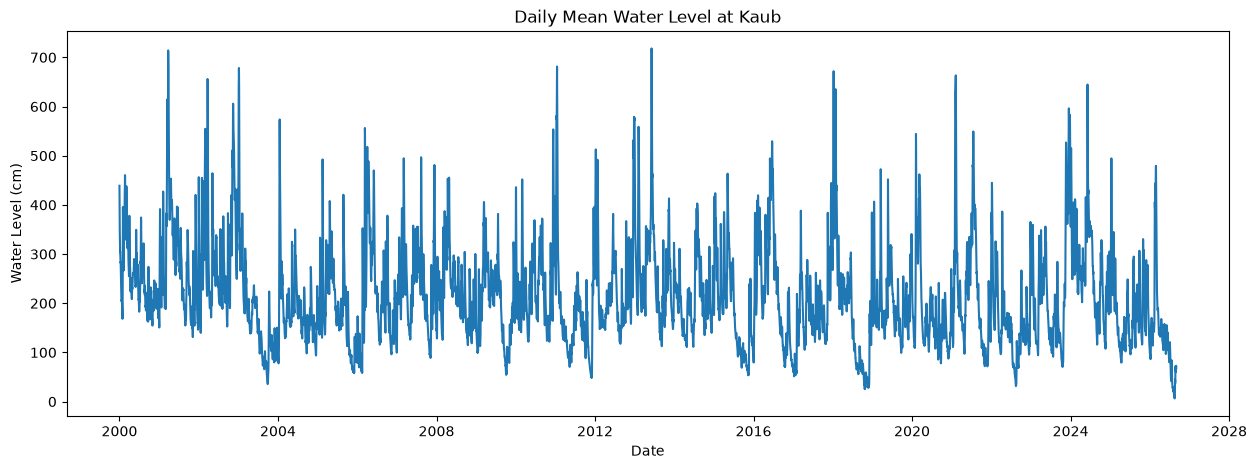

In [52]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))
plt.plot(daily_df["date"], daily_df["water_level_mean"])
plt.xlabel("Date")
plt.ylabel("Water Level (cm)")
plt.title("Daily Mean Water Level at Kaub")
plt.show()

In [53]:
daily_df["water_level_mean"].describe()

count    9741.000000
mean      214.472941
std       100.796160
min         6.416667
25%       145.229167
50%       197.020833
75%       264.906250
max       718.145833
Name: water_level_mean, dtype: float64

In [54]:
daily_df.nsmallest(20, "water_level_mean")[
    ["date", "water_level_mean", "water_level_min", "water_level_max"]
]

,date,water_level_mean,water_level_min,water_level_max
9725,2026-08-17,6.416667,5.00,9.00
9724,2026-08-16,6.739583,6.00,8.00
9723,2026-08-15,8.052083,6.00,10.25
9722,2026-08-14,8.135417,6.00,12.00
9720,2026-08-12,11.322917,10.00,13.00
9721,2026-08-13,11.916667,10.50,13.50
9726,2026-08-18,11.958333,9.00,14.75
9727,2026-08-19,13.906250,11.00,21.75
9719,2026-08-11,14.614583,13.75,16.50
9718,2026-08-10,16.510417,15.50,19.00


In [55]:
daily_df.nlargest(20, "water_level_mean")[
    ["date", "water_level_mean", "water_level_min", "water_level_max"]
]

,date,water_level_mean,water_level_min,water_level_max
4904,2013-06-05,718.145833,716.50,719.00
449,2001-03-25,714.130435,710.00,716.25
4903,2013-06-04,714.125000,710.25,716.00
450,2001-03-26,709.437500,703.00,714.50
4905,2013-06-06,705.718750,690.25,716.25
451,2001-03-27,693.229167,684.25,702.50
448,2001-03-24,690.104167,660.00,709.00
4033,2011-01-16,681.364583,669.25,688.00
4902,2013-06-03,678.583333,639.50,709.50
1101,2003-01-06,678.406250,673.75,680.00


In [56]:
hour_count = (
    merged_df.groupby("date")
    .size()
    .reset_index(name="hours_available")
)

daily_check = daily_df.merge(
    hour_count,
    on="date",
    how="left"
)

daily_check.nsmallest(20, "water_level_mean")[
    ["date", "water_level_mean", "water_level_min",
     "water_level_max", "hours_available"]
]

,date,water_level_mean,water_level_min,water_level_max,hours_available
9725,2026-08-17,6.416667,5.00,9.00,24
9724,2026-08-16,6.739583,6.00,8.00,24
9723,2026-08-15,8.052083,6.00,10.25,24
9722,2026-08-14,8.135417,6.00,12.00,24
9720,2026-08-12,11.322917,10.00,13.00,24
9721,2026-08-13,11.916667,10.50,13.50,24
9726,2026-08-18,11.958333,9.00,14.75,24
9727,2026-08-19,13.906250,11.00,21.75,24
9719,2026-08-11,14.614583,13.75,16.50,24
9718,2026-08-10,16.510417,15.50,19.00,24


In [57]:
daily_df.nsmallest(20, "water_level_mean")[
    ["date", "water_level_mean", "water_level_min", "water_level_max"]
]

,date,water_level_mean,water_level_min,water_level_max
9725,2026-08-17,6.416667,5.00,9.00
9724,2026-08-16,6.739583,6.00,8.00
9723,2026-08-15,8.052083,6.00,10.25
9722,2026-08-14,8.135417,6.00,12.00
9720,2026-08-12,11.322917,10.00,13.00
9721,2026-08-13,11.916667,10.50,13.50
9726,2026-08-18,11.958333,9.00,14.75
9727,2026-08-19,13.906250,11.00,21.75
9719,2026-08-11,14.614583,13.75,16.50
9718,2026-08-10,16.510417,15.50,19.00


In [58]:
hours_per_day = (
    merged_df
    .groupby("date")
    .size()
    .reset_index(name="hours_available")
)

hours_per_day["hours_available"].value_counts().sort_index()

hours_available
23       1
24    9740
Name: count, dtype: int64

In [59]:
daily_check = daily_df.merge(
    hours_per_day,
    on="date",
    how="left"
)

In [60]:
daily_check.nsmallest(20, "water_level_mean")[
    [
        "date",
        "water_level_mean",
        "water_level_min",
        "water_level_max",
        "hours_available"
    ]
]

,date,water_level_mean,water_level_min,water_level_max,hours_available
9725,2026-08-17,6.416667,5.00,9.00,24
9724,2026-08-16,6.739583,6.00,8.00,24
9723,2026-08-15,8.052083,6.00,10.25,24
9722,2026-08-14,8.135417,6.00,12.00,24
9720,2026-08-12,11.322917,10.00,13.00,24
9721,2026-08-13,11.916667,10.50,13.50,24
9726,2026-08-18,11.958333,9.00,14.75,24
9727,2026-08-19,13.906250,11.00,21.75,24
9719,2026-08-11,14.614583,13.75,16.50,24
9718,2026-08-10,16.510417,15.50,19.00,24


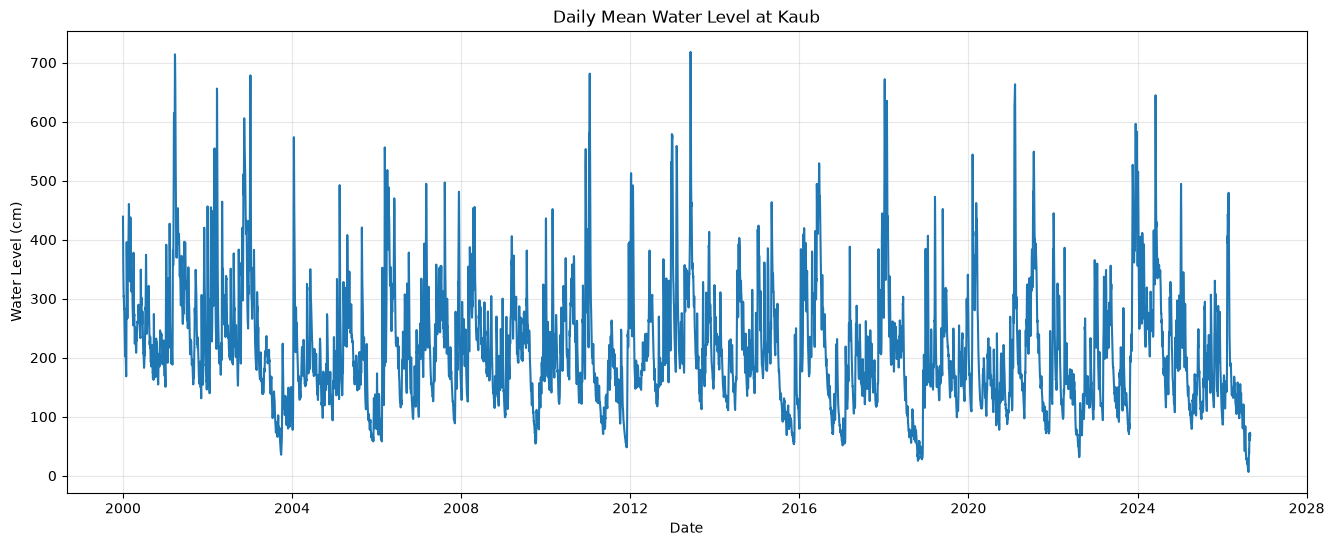

In [61]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.plot(
    daily_df["date"],
    daily_df["water_level_mean"]
)

plt.xlabel("Date")
plt.ylabel("Water Level (cm)")
plt.title("Daily Mean Water Level at Kaub")

plt.grid(alpha=0.3)
plt.show()

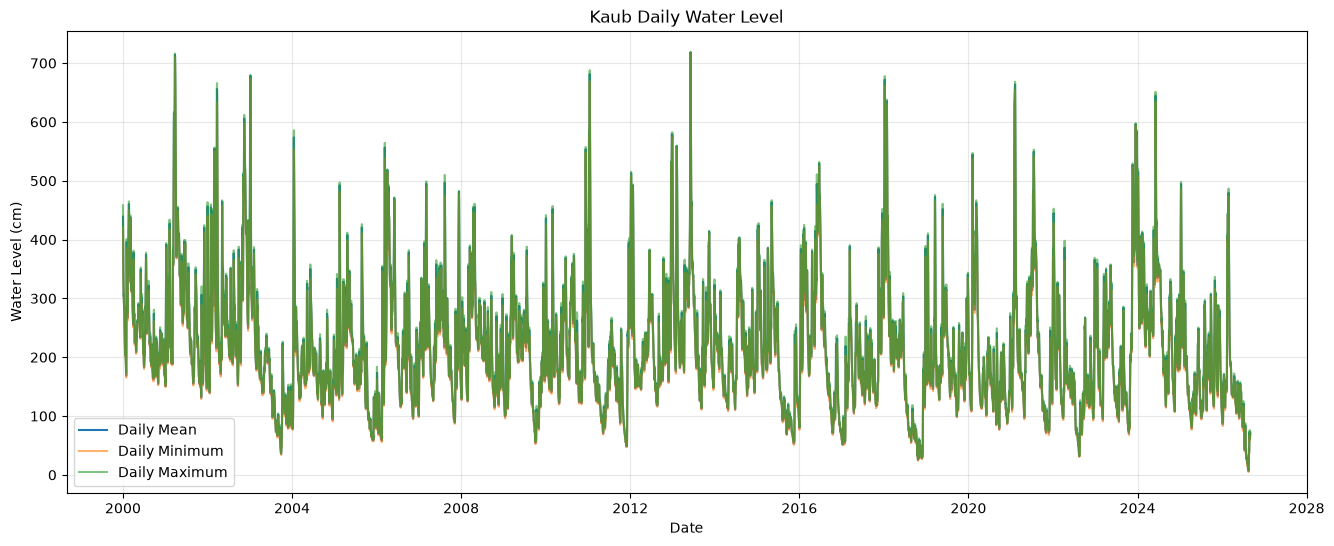

In [62]:
plt.figure(figsize=(16, 6))

plt.plot(
    daily_df["date"],
    daily_df["water_level_mean"],
    label="Daily Mean"
)

plt.plot(
    daily_df["date"],
    daily_df["water_level_min"],
    label="Daily Minimum",
    alpha=0.6
)

plt.plot(
    daily_df["date"],
    daily_df["water_level_max"],
    label="Daily Maximum",
    alpha=0.6
)

plt.xlabel("Date")
plt.ylabel("Water Level (cm)")
plt.title("Kaub Daily Water Level")

plt.legend()
plt.grid(alpha=0.3)
plt.show()